In [1]:
# This basic script shows how to use CLASS to plot the CMB spectrum
# of temperature, polarisation and lensing potential, as well as the matter power spectrum

In [2]:
# import classy module
from classy import Class

In [3]:
# create an instance of CLASS
LambdaCDM = Class()

####################################################
#
# Cosmological parameters and other CLASS parameters
#
####################################################
input = {# LambdaCDM parameters (Planck 18 + lensing + BAO bestfit)
        'omega_b':2.255065e-02,
        'omega_cdm':1.193524e-01,
        'H0':6.776953e+01,
        'A_s':2.123257e-09,
        'n_s':9.686025e-01,
        'z_reio':8.227371e+00,
        # other fixed parameters
        'N_ur':2.0328,
        'N_ncdm':1,
        'm_ncdm':0.06,
        'T_ncdm':0.71611,
        'hierarchy':'TAM',
        # settings for the output quantites
        'output':'tCl, pCl, lCl',
        'lensing':'yes',
        }
LambdaCDM.set(input)

# Note that you could get all the same settings in just one line with the pre-set command
# LambdaCDM.set_baseline('p18lb')
# Here 'p18lb' is a short-cut for Planck18 + lensing + BAO bestfit
# other options are 'p18l' and 'p18'
# These pre-settings are defined in the classy function .set_baseline()

# In older versions of classy one needed to execute CLASS with .compute()
# This is no longer necessary, the code execution happens directly when calling classy functions

True

In [6]:
import sys
import classy
from classy import _classy

print(sys.executable)
print(_classy.__file__)
print(LambdaCDM.pars.get('output'))
cls = LambdaCDM.raw_cl(lmax=2500)
print(cls.keys())

/Users/derinsivrioglu/miniconda3/envs/cmbgood/bin/python
/Users/derinsivrioglu/miniconda3/envs/cmbgood/lib/python3.12/site-packages/classy/_classy.cpython-312-darwin.so
tCl, pCl, lCl
dict_keys(['tt', 'ee', 'te', 'bb', 'pp', 'tp', 'eb', 'tb', 'ell'])


In [5]:
# get lesned C_l spectra
cls = LambdaCDM.raw_cl(2500)
# To check the format of cls
cls.keys()

dict_keys(['tt', 'ee', 'te', 'bb', 'pp', 'tp', 'eb', 'tb', 'ell'])

In [6]:
# get multipoles l
ll = cls['ell'][2:]
# get CMB temperature spectrum C_l^TT
clTT = cls['tt'][2:]
# get CMB polarisation spectrum C_l^EE
clEE = cls['ee'][2:]
# get CMB polarisation spectrum C_l^BB
clBB = cls['bb'][2:]
# get CMB cross-polarisation spectrum C_l^EB
clEB = cls['eb'][2:]
# get CMB cross-polarisation spectrum C_l^TB
clTB = cls['tb'][2:]

In [8]:
# uncomment to get plots displayed in notebook
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

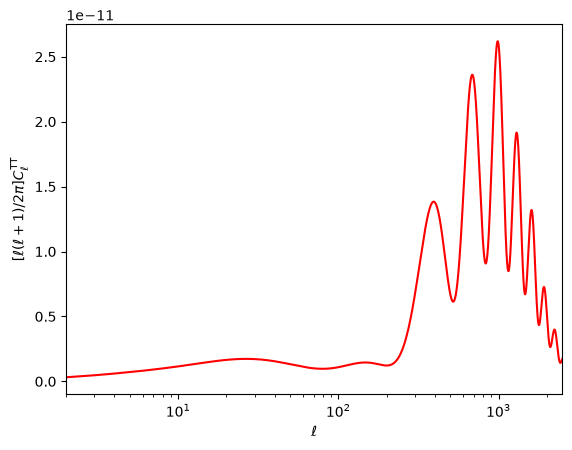

In [9]:
# plot C_l^TT
plt.figure(1)
plt.xscale('log');plt.yscale('linear');plt.xlim(2,2500)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$[\ell(\ell+1)/2\pi]  C_\ell^\mathrm{TT}$')
plt.plot(ll,clTT*ll*(ll+1)/(2.*np.pi),'r-')
plt.savefig('warmup_cltt.pdf')

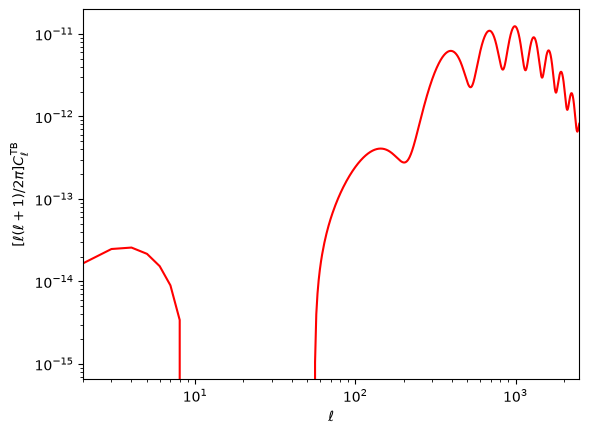

In [16]:
# plot C_l^EE
plt.figure(1)
plt.xscale('log');plt.yscale('log');plt.xlim(2,2500)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$[\ell(\ell+1)/2\pi]  C_\ell^\mathrm{TB}$')
plt.plot(ll,clTB*ll*(ll+1)/(2.*np.pi),'r-')
plt.savefig('warmup_clee.pdf')

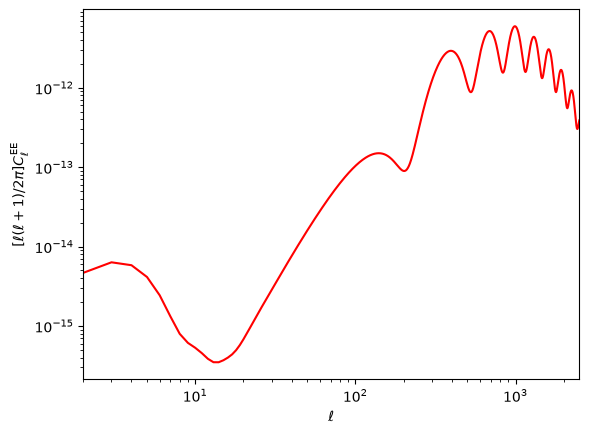

In [12]:
# plot C_l^EE
plt.figure(1)
plt.xscale('log');plt.yscale('log');plt.xlim(2,2500)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$[\ell(\ell+1)/2\pi]  C_\ell^\mathrm{EE}$')
plt.plot(ll,clEE*ll*(ll+1)/(2.*np.pi),'r-')
plt.savefig('warmup_clee.pdf')

In [10]:
# get P(k) at redhsift z=0
import numpy as np
kk = np.geomspace(1e-4,3.0,num=1000) # k in h/Mpc
h = LambdaCDM.h() # get reduced Hubble for conversions to h/Mpc
# Note that kk*h is the array of k in 1/Mpc
Pk = LambdaCDM.get_pk_all(kk*h,0.)*h**3 # get power spectrum, converted into (Mpc/h)^3 units, instead of the default Mpc^3 units
# By default, this is the non-linear matter power spectrum; to get the linear one,
# pass the optional argument 'nonlinear=False' to .get_pk_all()

In [ ]:
# plot P(k)
plt.figure(2)
plt.xscale('log');plt.yscale('log');plt.xlim(kk[0],kk[-1])
plt.xlabel(r'$k \,\,\,\, [h/\mathrm{Mpc}]$')
plt.ylabel(r'$P(k) \,\,\,\, [\mathrm{Mpc}/h]^3$')
plt.plot(kk,Pk,'b-')
plt.savefig('warmup_pk.pdf')